# Implementation 4: SOR for Gaussian Process Regression

**Math 455 Midterm Project: Relaxation Methods**

Implementation 3 applied SOR to the sparse systems that come from differential equations, where it works
well. This notebook tests a different application: **Gaussian process regression** (GPR), proposed in the
theory write-up *Gaussian Process Regression at Large Sample Sizes*. Almost all of the work in GPR is one
linear system,

$$(K + \sigma^2 I)\,\boldsymbol{\alpha} = \mathbf{y},$$

where $K$ is the $n \times n$ covariance matrix of the $n$ training inputs. This matrix is symmetric positive
definite, so by Theorem 7.25 SOR converges for every $0 < \omega < 2$. Unlike the PDE matrices, it is
**dense**: no entry is zero. The question is whether a well-chosen $\omega$ makes SOR a practical way to
solve it. The notebook

1. builds a GPR system and checks the solvers on it (Tests 4.1 to 4.3);
2. decides how accurately the system actually needs to be solved;
3. studies $\omega$ for several kernel settings;
4. compares Gauss-Seidel, SOR, Cholesky factorization and the conjugate gradient method (Section 7.6) as the
   number of observations $n$ grows.

Three figures for the report are saved to `figures/`. The notebook takes about two minutes to run.

In [1]:
import contextlib
import io
import os
import time
from collections import namedtuple

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import cho_factor, cho_solve, solve_triangular

os.makedirs("figures", exist_ok=True)

## Tools from Implementations 1 to 3

`sor` (Algorithm 7.3) and the iteration-matrix helpers are copied unchanged from the earlier notebooks,
with the class convention $A = D + L + U$ (diagonal, strictly lower and strictly upper parts).

In [2]:
SORResult = namedtuple("SORResult", ["x", "iterations", "converged", "history"])


def sor(A, b, x0, omega, tol, max_iter, norm=np.inf):
    '''Solve Ax = b by SOR (Burden, Faires & Burden, Algorithm 7.3).

    Returns SORResult(x, iterations, converged, history), where history[k] is
    the iterate x^(k) and history[0] is x0.
    '''
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    XO = np.array(x0, dtype=float)
    n = len(b)

    if np.any(np.diag(A) == 0):
        raise ValueError("SOR requires every diagonal entry a_ii to be nonzero")

    x = np.zeros(n)
    history = [XO.copy()]

    k = 1                                                     # Step 1
    while k <= max_iter:                                      # Step 2
        for i in range(n):                                    # Step 3
            x[i] = (1 - omega) * XO[i] + (1 / A[i, i]) * (
                omega * (-A[i, :i] @ x[:i] - A[i, i + 1:] @ XO[i + 1:] + b[i])
            )
        history.append(x.copy())

        if np.linalg.norm(x - XO, norm) < tol:                # Step 4
            return SORResult(x.copy(), k, True, history)

        k += 1                                                # Step 5
        XO = x.copy()                                         # Step 6

    print("Maximum number of iterations exceeded")            # Step 7
    return SORResult(x.copy(), max_iter, False, history)


def split(A):
    '''Return D, L, U with A = D + L + U (class convention).'''
    A = np.asarray(A, dtype=float)
    return np.diag(np.diag(A)), np.tril(A, -1), np.triu(A, 1)


def jacobi_matrix(A):
    D, L, U = split(A)
    return -np.linalg.solve(D, L + U)


def sor_matrix(A, omega):
    D, L, U = split(A)
    return np.linalg.solve(D + omega * L, (1 - omega) * D - omega * U)


def spectral_radius(T):
    return np.max(np.abs(np.linalg.eigvals(T)))

## Gaussian process regression

A Gaussian process treats the unknown function $f$ as random: any finite set of values
$f(x_1), \dots, f(x_n)$ has a joint normal distribution with mean $0$ and covariances given by a
**kernel** $k(x, x')$. This notebook uses the squared-exponential kernel

$$k(x, x') = \exp\!\left(-\frac{(x - x')^2}{2\ell^2}\right),$$

where the **length scale** $\ell$ says how far apart two inputs can be and still have strongly related
function values. The data are noisy observations $y_i = f(x_i) + \varepsilon_i$, with independent noise of
variance $\sigma^2$. At test inputs $X_*$, the prediction is the posterior mean
(Rasmussen and Williams, Eq. 2.25)

$$\boldsymbol{\mu}_* = K(X_*, X)\,\boldsymbol{\alpha}, \qquad \text{where } (K + \sigma^2 I)\,\boldsymbol{\alpha} = \mathbf{y},$$

and $K_{ij} = k(x_i, x_j)$. The posterior variance needs a further solve for every test input, so the
iterative solvers below are only used for the mean. The standard method (their Algorithm 2.1) is Cholesky
factorization, which costs about $n^3/3$ operations (Section 6.6).

The hyperparameters $\ell$ and $\sigma^2$ are fixed here rather than fitted to the data. Fitting them needs
the determinant of $K + \sigma^2 I$ as well, which is beyond this project.

**Test data.** Inputs are drawn uniformly on $[0, 1]$ and sorted, and
$y_i = \sin(2\pi x_i) + \tfrac12\cos(5\pi x_i) + \varepsilon_i$. The main example has $n = 300$,
$\ell = 0.1$ and $\sigma^2 = 0.01$ (noise standard deviation $0.1$). Predictions are made at 201 evenly
spaced test points.

In [3]:
def kernel(s, t, ell):
    '''Squared-exponential kernel exp(-(s - t)^2 / (2 ell^2)) for every pair of entries of s and t.'''
    return np.exp(-np.subtract.outer(s, t) ** 2 / (2 * ell**2))


def true_function(t):
    return np.sin(2 * np.pi * t) + 0.5 * np.cos(5 * np.pi * t)


GPR = namedtuple("GPR", ["x", "y", "A", "K_star", "x_star", "ell", "noise_var"])


def gpr_problem(n, ell, noise_var, seed=455):
    '''n sorted random inputs on [0, 1], noisy observations, A = K + sigma^2 I, and K(X_*, X).'''
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    y = true_function(x) + np.sqrt(noise_var) * rng.standard_normal(n)
    x_star = np.linspace(0, 1, 201)
    A = kernel(x, x, ell) + noise_var * np.eye(n)
    return GPR(x, y, A, kernel(x_star, x, ell), x_star, ell, noise_var)


def direct_solve(problem):
    '''Cholesky factorization A = L L^t, then two triangular solves (the reference answer).'''
    return cho_solve(cho_factor(problem.A), problem.y)


def mean_error(problem, alpha_exact):
    '''Return error(alpha): the largest error in the predictive mean, relative to max |mu_*|.'''
    mu = problem.K_star @ alpha_exact
    scale = np.max(np.abs(mu))
    return lambda alpha: np.max(np.abs(problem.K_star @ alpha - mu)) / scale


MAIN = gpr_problem(300, ell=0.1, noise_var=0.01)
ALPHA_MAIN = direct_solve(MAIN)

### Test 4.1: The GPR matrix is symmetric positive definite, and dense

$K$ is a covariance matrix, so it is symmetric with eigenvalues $\ge 0$. Adding $\sigma^2 I$ shifts every
eigenvalue up by $\sigma^2$, so $A = K + \sigma^2 I$ is positive definite with smallest eigenvalue at least
$\sigma^2$. Every diagonal entry is $k(x_i, x_i) + \sigma^2 = 1 + \sigma^2 \neq 0$, so Algorithm 7.3 can be
applied. The test also checks that Cholesky agrees with Gaussian elimination (`np.linalg.solve`).

In [4]:
A = MAIN.A
eigs = np.linalg.eigvalsh(A)
off_diagonal = np.sum(np.abs(A), axis=1) - np.abs(np.diag(A))

assert np.array_equal(A, A.T)
assert eigs.min() >= MAIN.noise_var - 1e-10
assert np.all(np.diag(A) == 1 + MAIN.noise_var)
assert np.allclose(ALPHA_MAIN, np.linalg.solve(A, MAIN.y), rtol=1e-8, atol=1e-8)

print(f"n = {len(A)}: entries above 0.01 in size: {np.mean(np.abs(A) > 0.01):.0%}; none are zero: {np.all(A > 0)}")
print(f"eigenvalues from {eigs.min():.4f} to {eigs.max():.1f}; condition number K_2(A) = {eigs.max() / eigs.min():.0f}")
print(f"off-diagonal row sums are up to {off_diagonal.max() / (1 + MAIN.noise_var):.0f} times the diagonal entry")
print("PASS: A is symmetric positive definite, lambda_min >= sigma^2, and Cholesky matches elimination")

n = 300: entries above 0.01 in size: 52%; none are zero: True
eigenvalues from 0.0100 to 76.5; condition number K_2(A) = 7651
off-diagonal row sums are up to 85 times the diagonal entry
PASS: A is symmetric positive definite, lambda_min >= sigma^2, and Cholesky matches elimination


Two facts here matter later. The matrix is **far from diagonally dominant**: each off-diagonal row sum is
many times the diagonal, because every input has dozens of neighbours within one length scale. So Theorem
7.21 gives no guarantee for Jacobi. And the condition number is large, because the smallest eigenvalue is
only about $\sigma^2$ while the largest grows with the number of correlated neighbours.

### A faster sweep with the same arithmetic

Algorithm 7.3 is written component by component, and a Python loop over $i$ is slow for large $n$. The same
sweep in matrix form is

$$(D + \omega L)\,\mathbf{x}^{(k)} = \big[(1 - \omega)D - \omega U\big]\,\mathbf{x}^{(k-1)} + \omega\,\mathbf{b}.$$

Solving the lower-triangular system by forward substitution performs exactly the updates of Step 3 in
order, using new values for $j < i$ and old values for $j > i$. `scipy`'s `solve_triangular` does this in
compiled code. Each sweep still costs about $2n^2$ operations.

`sor_until` runs this sweep from $\mathbf{x}^{(0)} = \mathbf{0}$ until a given error measure falls below a
target, and returns the number of sweeps. `cg_until` does the same for the conjugate gradient method,
Algorithm 7.5 with no preconditioning ($C = I$), written in the book's notation: residual
$\mathbf{r}^{(k)}$, search direction $\mathbf{v}^{(k)}$ and step sizes $t_k$, $s_k$. Each CG iteration also
costs about $2n^2$ operations, for one product $A\mathbf{v}$.

In [5]:
def sor_sweep(A, b, omega):
    '''Return the map x^(k-1) -> x^(k) of one SOR sweep, in matrix form.'''
    D, L, U = split(A)
    lower = D + omega * L
    right = (1 - omega) * D - omega * U
    wb = omega * np.asarray(b, dtype=float)
    return lambda x: solve_triangular(lower, right @ x + wb, lower=True, check_finite=False)


def sor_until(A, b, omega, error, target, max_iter):
    '''SOR from x0 = 0 until error(x) < target. Returns (sweeps, x); sweeps is None if max_iter is reached.'''
    step = sor_sweep(A, b, omega)
    x = np.zeros(len(b))
    for k in range(1, max_iter + 1):
        x = step(x)
        if error(x) < target:
            return k, x
    return None, x


def cg_until(A, b, error, target, max_iter):
    '''Conjugate gradient method (Algorithm 7.5 with C = I) from x0 = 0. Same returns as sor_until.'''
    x = np.zeros(len(b))
    r = np.asarray(b, dtype=float).copy()
    v = r.copy()
    rr = r @ r
    for k in range(1, max_iter + 1):
        Av = A @ v
        t = rr / (v @ Av)
        x = x + t * v
        r = r - t * Av
        if error(x) < target:
            return k, x
        rr_new = r @ r
        v = r + (rr_new / rr) * v
        rr = rr_new
    return None, x

### Test 4.2: The new solvers are correct

* One matrix-form sweep must equal one sweep of Algorithm 7.3 (`sor` with $N = 1$), for several $\omega$.
* Algorithm 7.3 itself must converge to the Cholesky answer on a small GPR system ($n = 40$).
* CG must reproduce Section 7.6, Example 1: on the Example 1 system from Section 7.4 it reaches the exact
  solution $(3, 4, -5)^t$ in 3 iterations, as Theorem 7.32 guarantees for a $3 \times 3$ system.

In [6]:
small = gpr_problem(40, ell=0.1, noise_var=0.01)
x_random = np.random.default_rng(0).standard_normal(40)
for omega in [0.3, 1.0, 1.5]:
    with contextlib.redirect_stdout(io.StringIO()):  # N = 1 always ends with Step 7's message
        one_sweep = sor(small.A, small.y, x_random, omega, tol=0, max_iter=1)
    assert np.allclose(one_sweep.x, sor_sweep(small.A, small.y, omega)(x_random), rtol=0, atol=1e-12)

alpha_small = direct_solve(small)
result = sor(small.A, small.y, np.zeros(40), omega=0.5, tol=1e-12, max_iter=100_000)
small_error = np.max(np.abs(result.x - alpha_small)) / np.max(np.abs(alpha_small))
assert result.converged and small_error < 1e-8

A_ex1 = np.array([[4.0, 3, 0], [3, 4, -1], [0, -1, 4]])
b_ex1 = np.array([24.0, 30, -24])
cg_steps, x_cg = cg_until(A_ex1, b_ex1, lambda x: np.max(np.abs(x - [3, 4, -5])), 1e-12, 10)
assert cg_steps == 3

print(f"Algorithm 7.3 on the n = 40 GPR system: {result.iterations} iterations, relative error {small_error:.1e}")
print(f"CG on Example 1: exact solution after {cg_steps} iterations, x = {np.round(x_cg, 12)}")
print("PASS: matrix-form sweep = Algorithm 7.3, SOR matches Cholesky, CG reproduces Section 7.6 Example 1")

Algorithm 7.3 on the n = 40 GPR system: 4718 iterations, relative error 9.5e-12
CG on Example 1: exact solution after 3 iterations, x = [ 3.  4. -5.]
PASS: matrix-form sweep = Algorithm 7.3, SOR matches Cholesky, CG reproduces Section 7.6 Example 1


### Test 4.3: Theorems 7.24 to 7.26 on the GPR matrix

* **Theorem 7.24 (Kahan):** $\rho(T_\omega) \ge |\omega - 1|$ for every $\omega$.
* **Theorem 7.25 (Ostrowski-Reich):** $A$ is positive definite, so $\rho(T_\omega) < 1$ for every
  $0 < \omega < 2$.
* **Theorem 7.26** gives the optimal $\omega = 2/\big(1 + \sqrt{1 - \rho(T_J)^2}\big)$, but only for a
  positive definite **tridiagonal** matrix. $A$ is dense, so the theorem does not apply. The test shows that
  its formula cannot even be evaluated: $\rho(T_J) > 1$, so Jacobi diverges and $1 - \rho(T_J)^2 < 0$.
  Its other conclusion, $\rho(T_g) = \rho(T_J)^2$, fails as well.

The optimal $\omega$ is therefore found by computing $\rho(T_\omega)$ on a grid of $\omega$ values, as in
Implementation 2. This takes a few seconds.

In [7]:
GPR_OMEGAS = np.round(np.arange(0.05, 1.951, 0.05), 2)
RHO_MAIN = np.array([spectral_radius(sor_matrix(MAIN.A, w)) for w in GPR_OMEGAS])
rho_J = spectral_radius(jacobi_matrix(MAIN.A))
rho_GS = RHO_MAIN[GPR_OMEGAS == 1.0][0]

assert np.all(RHO_MAIN >= np.abs(GPR_OMEGAS - 1) - 1e-12)   # Theorem 7.24
assert np.all(RHO_MAIN < 1)                             # Theorem 7.25
assert rho_J > 1 and rho_GS < 1                         # Theorem 7.26 does not apply

i_best = np.argmin(RHO_MAIN)
W_BEST_RHO = GPR_OMEGAS[i_best]


def sweeps_per_digit(rho):
    '''Sweeps that reduce the error by a factor of 10, from ||e_k|| ~ rho^k ||e_0|| (Eq. 7.12).'''
    return 1 / -np.log10(rho)


print(f"rho(T_J) = {rho_J:.1f}  (Jacobi diverges)")
print(f"Gauss-Seidel: rho = {rho_GS:.6f}, about {sweeps_per_digit(rho_GS):,.0f} sweeps per decimal digit")
print(f"best omega on the grid = {W_BEST_RHO}: rho = {RHO_MAIN[i_best]:.6f}, "
      f"about {sweeps_per_digit(RHO_MAIN[i_best]):,.0f} sweeps per decimal digit")
print(f"omega = 1.5: rho = {RHO_MAIN[GPR_OMEGAS == 1.5][0]:.6f}")
print("PASS: Theorems 7.24 and 7.25 hold; Theorem 7.26 does not apply, and the best omega is below 1")

rho(T_J) = 74.8  (Jacobi diverges)
Gauss-Seidel: rho = 0.999889, about 20,709 sweeps per decimal digit
best omega on the grid = 0.15: rho = 0.999231, about 2,993 sweeps per decimal digit
omega = 1.5: rho = 0.999963
PASS: Theorems 7.24 and 7.25 hold; Theorem 7.26 does not apply, and the best omega is below 1


The best $\omega$ is well **below 1**: under-relaxation, as for Homework 3 #14 in Implementation 2, and the
opposite of the PDE problems in Implementation 3. Even so, every spectral radius is extremely close to 1.
By Eq. (7.12), $\|\mathbf{x}^{(k)} - \mathbf{x}\| \approx \rho(T_\omega)^k\,\|\mathbf{x}^{(0)} - \mathbf{x}\|$,
so each extra decimal digit of $\boldsymbol\alpha$ costs thousands of sweeps. This is more than the
$n/6 = 50$ sweeps that would cost as much as a Cholesky factorization (see the scaling study).

## How accurately does the system need to be solved?

Two observations change how SOR should be judged here.

1. **Only the prediction matters.** What a user needs is $\boldsymbol\mu_* = K(X_*, X)\boldsymbol\alpha$,
   not $\boldsymbol\alpha$ itself. The slowest error components of $\boldsymbol\alpha$ lie along the
   eigenvectors of $K$ with the smallest eigenvalues, and multiplying by $K(X_*, X)$ shrinks exactly those
   components. So $\boldsymbol\mu_*$ can be accurate before $\boldsymbol\alpha$ is.
2. **The model has its own uncertainty.** The posterior standard deviation says how far the prediction can be
   trusted. Solving far more accurately than that does not make the prediction better, just as in
   Implementation 3 the linear system only needed to be solved to below the discretization error.

From here on, a solve counts as accurate when the predictive mean is within **0.1%**:
$\max|\boldsymbol\mu_*^{(k)} - \boldsymbol\mu_*| < 10^{-3}\max|\boldsymbol\mu_*|$. The cell below runs
Gauss-Seidel on the main example and records when this happens, when $\boldsymbol\alpha$ itself reaches the
same relative accuracy, and when Algorithm 7.3's own stopping rule $\|\mathbf{x}^{(k)} - \mathbf{x}^{(k-1)}\|_\infty < TOL$
would stop. It takes about ten seconds.

In [8]:
TARGET = 1e-3
ERROR_MAIN = mean_error(MAIN, ALPHA_MAIN)
mu_main = MAIN.K_star @ ALPHA_MAIN

factor = cho_factor(MAIN.A)
posterior_var = 1 - np.sum(MAIN.K_star * cho_solve(factor, MAIN.K_star.T).T, axis=1)
POSTERIOR_SD = np.sqrt(np.maximum(posterior_var, 0))

TOLS = [1e-2, 1e-3, 1e-4]
alpha_scale = np.max(np.abs(ALPHA_MAIN))
step = sor_sweep(MAIN.A, MAIN.y, 1.0)
alpha = np.zeros(300)
first, stops = {}, {}
for k in range(1, 300_001):
    new = step(alpha)
    change = np.max(np.abs(new - alpha))
    alpha = new
    for tol in TOLS:
        if tol not in stops and change < tol:
            stops[tol] = (k, change, ERROR_MAIN(alpha), np.max(np.abs(alpha - ALPHA_MAIN)))
    if "mean" not in first and ERROR_MAIN(alpha) < TARGET:
        first["mean"] = k
    if "alpha" not in first and np.max(np.abs(alpha - ALPHA_MAIN)) < TARGET * alpha_scale:
        first["alpha"] = k
    if len(first) == 2 and len(stops) == len(TOLS):
        break

print(f"max |mu_*| = {np.max(np.abs(mu_main)):.2f}, so 0.1% is {TARGET * np.max(np.abs(mu_main)):.4f}; "
      f"the posterior standard deviation is between {POSTERIOR_SD.min():.3f} and {POSTERIOR_SD.max():.3f}")
print(f"Gauss-Seidel sweeps until mu_* is within 0.1%:   {first['mean']:>7,}")
alpha_sweeps = f"{first['alpha']:,}" if "alpha" in first else "> 300,000"
print(f"Gauss-Seidel sweeps until alpha is within 0.1%:  {alpha_sweeps:>7}   (max |alpha| = {alpha_scale:.0f})")
print(f"\nAlgorithm 7.3's stopping rule, Gauss-Seidel (rho/(1 - rho) = {rho_GS / (1 - rho_GS):,.0f}):")
print(f"{'TOL':>6} {'stops after':>12} {'error in alpha':>15} {'error in mu_*':>14}")
for tol, (k, change, mu_err, alpha_err) in stops.items():
    print(f"{tol:>6g} {k:>12,} {alpha_err:>15.3g} {mu_err:>14.2%}")

max |mu_*| = 1.17, so 0.1% is 0.0012; the posterior standard deviation is between 0.017 and 0.052
Gauss-Seidel sweeps until mu_* is within 0.1%:    17,263
Gauss-Seidel sweeps until alpha is within 0.1%:   44,715   (max |alpha| = 27)

Algorithm 7.3's stopping rule, Gauss-Seidel (rho/(1 - rho) = 8,993):
   TOL  stops after  error in alpha  error in mu_*
  0.01        2,122            4.64          0.74%
 0.001       16,025           0.678          0.16%
0.0001       36,251          0.0689          0.01%


The predictive mean is accurate about 2.6 times sooner than $\boldsymbol\alpha$ (17,263 sweeps against
44,715), so all comparisons below count sweeps until $\boldsymbol\mu_*$ is within 0.1%. That target is about
0.001, well below the posterior standard deviation of 0.017 to 0.052, so it is accurate enough for any use of
the prediction.

**Algorithm 7.3's stopping rule is unreliable here.** With $TOL = 10^{-2}$, Gauss-Seidel stops while the
error in $\boldsymbol\alpha$ is still about 460 times $TOL$, and the prediction is off by 0.7%. With
$TOL = 10^{-3}$ the error is about 680 times $TOL$. When $\rho(T)$ is close to 1, the iterates change very
little per sweep even while the error is large. Summing the remaining changes as a geometric series, the
error can be up to about $\rho/(1 - \rho)$ times the last change, which is about 9,000 here. A small change
between sweeps does not mean the answer is close, so a stopping rule for GPR should be based on something
else, such as the residual $\mathbf{y} - A\boldsymbol\alpha^{(k)}$ (Section 7.5).

## Choosing $\omega$ for different kernels

The length scale $\ell$ and the noise $\sigma^2$ control the conditioning of $A$ (the theory write-up's main
point about kernels). The cell below takes six combinations, all with $n = 300$, and for each one counts the
sweeps SOR needs on a grid of $\omega$ values, up to a limit of 20,000 sweeps. For comparison it also counts
CG iterations. It takes about a minute.

In [9]:
SETTINGS = [(0.02, 0.1), (0.02, 0.01), (0.05, 0.1), (0.05, 0.01), (0.1, 0.1), (0.1, 0.01)]
SWEEP_OMEGAS = np.round(np.r_[np.arange(0.05, 1.001, 0.05), [1.2, 1.4, 1.6, 1.8]], 2)
MAX_SWEEPS = 20_000
STUDY = {}

print(f"{'ell':>5} {'sigma^2':>8} {'K_2(A)':>8} {'rho(T_J)':>9} {'G-S':>7} {'best w':>7} {'SOR':>6} {'CG':>4}")
for ell, noise_var in SETTINGS:
    p = gpr_problem(300, ell, noise_var)
    alpha_exact = direct_solve(p)
    error = mean_error(p, alpha_exact)
    sweeps = np.array([sor_until(p.A, p.y, w, error, TARGET, MAX_SWEEPS)[0] or np.nan for w in SWEEP_OMEGAS])
    i = np.nanargmin(sweeps)
    cg_steps = cg_until(p.A, p.y, error, TARGET, 300)[0]
    eigs = np.linalg.eigvalsh(p.A)
    STUDY[ell, noise_var] = dict(problem=p, sweeps=sweeps, w_best=SWEEP_OMEGAS[i], best=int(sweeps[i]),
                                 gs=sweeps[SWEEP_OMEGAS == 1.0][0], cg=cg_steps)
    gs = STUDY[ell, noise_var]["gs"]
    print(f"{ell:>5} {noise_var:>8} {eigs.max() / eigs.min():>8.0f} {spectral_radius(jacobi_matrix(p.A)):>9.1f} "
          f"{'>20000' if np.isnan(gs) else f'{gs:.0f}':>7} {SWEEP_OMEGAS[i]:>7} {sweeps[i]:>6.0f} {cg_steps:>4}")

print(f"\nA Cholesky factorization costs about as much as n/6 = {300 // 6} sweeps.")

  ell  sigma^2   K_2(A)  rho(T_J)     G-S  best w    SOR   CG


 0.02      0.1      223      19.3     326    0.55    135   39


 0.02     0.01     2224      21.0    2181     0.4   1037   79


 0.05      0.1      451      40.0    1264     0.2    241   26


 0.05     0.01     4503      43.6    7374    0.25   1583   40


  0.1      0.1      766      68.6    3271    0.15    443   17


  0.1     0.01     7651      74.8   17263     0.1   2403   21

A Cholesky factorization costs about as much as n/6 = 50 sweeps.


What the table shows:

* **The best $\omega$ is below 1 in every setting**, and it gets smaller as $\ell$ grows: about 0.4 to 0.55
  for $\ell = 0.02$, but 0.1 to 0.15 for $\ell = 0.1$. A longer length scale means each observation is
  strongly correlated with more neighbours. $\rho(T_J)$ is roughly that number of neighbours,
  $n\ell\sqrt{2\pi} \approx 15$, 38 and 75, because each row of $K$ sums to about this much.
* **Less noise makes every method slower.** Dividing $\sigma^2$ by 10 multiplies the condition number by
  about 10, and Gauss-Seidel's sweep count by 5 to 7.
* **SOR beats Gauss-Seidel by a factor of 2 to 7, but never comes close to Cholesky.** Even the easiest case
  needs 135 sweeps, almost three times the cost of a factorization ($n/6 = 50$ sweeps), and the hardest
  needs 2,403, about 50 times.
* **CG needs 17 to 79 iterations**, and unlike SOR it gets faster as $\ell$ grows. CG's speed depends on how
  the eigenvalues of $A$ are spread out, not only on the condition number. With a smooth kernel, only a few
  eigenvalues are large and the rest are close to $\sigma^2$, which suits CG.

### Does the order of the data matter?

Gauss-Seidel and SOR update the unknowns in a fixed order, so unlike Cholesky or CG, their speed depends on
how the observations are numbered. All the runs above use inputs sorted from left to right. The cell below
shuffles the main example's observations. This is the same system with the rows and columns permuted, so it
has the same solution, but the sweeps update the unknowns in a different order.

In [10]:
perm = np.random.default_rng(1).permutation(300)
SHUFFLED = MAIN._replace(x=MAIN.x[perm], y=MAIN.y[perm], A=MAIN.A[np.ix_(perm, perm)], K_star=MAIN.K_star[:, perm])
alpha_shuffled = direct_solve(SHUFFLED)
assert np.allclose(alpha_shuffled, ALPHA_MAIN[perm])

ORDER_OMEGAS = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0]
print(f"{'order':>9} " + " ".join(f"{'w=' + str(w):>7}" for w in ORDER_OMEGAS))
for name, p, a in [("sorted", MAIN, ALPHA_MAIN), ("shuffled", SHUFFLED, alpha_shuffled)]:
    counts = [sor_until(p.A, p.y, w, mean_error(p, a), TARGET, 100_000)[0] for w in ORDER_OMEGAS]
    print(f"{name:>9} " + " ".join(f"{c if c else '>1e5':>7}" for c in counts))

    order  w=0.05   w=0.1  w=0.15   w=0.2   w=0.3   w=0.5   w=1.0


   sorted    3028    2403    2491    2685    3298    6567   17263


 shuffled    6187    4689    7072    7167   10716   14680   33311


Shuffling about doubles the work for every $\omega$: 4,689 sweeps instead of 2,403 with the best $\omega$,
and 33,311 instead of 17,263 for Gauss-Seidel. The best $\omega$ stays near 0.1. Sorting places strongly
correlated observations next to each other, so each update immediately uses the new values of the
neighbours that matter most. Sorting is free for inputs on a line, but inputs in two or more dimensions
have no natural order.

## Scaling study: more observations

The theory write-up's motivation is large $n$. With a fixed length scale on a fixed interval, more data
means more neighbours within one length scale, so $A$ becomes worse conditioned as $n$ grows. The cell below
uses $\ell = 0.05$ and $\sigma^2 = 0.01$ and doubles $n$ from 100 to 800. For each $n$ it records

* the time for Cholesky (the best of 5 runs);
* the sweeps Gauss-Seidel needs, and the sweeps SOR needs with the best $\omega$ from a short list;
* the CG iterations;
* the **break-even count** $n/6$. Cholesky costs about $n^3/3$ operations and one sweep or CG iteration about
  $2n^2$, so an iterative method is only cheaper if it needs fewer than $n/6$ sweeps.

Times include checking the error after every sweep, which a real solver would not do, so the sweep counts
are the fair comparison, as in Implementation 3. This cell takes about a minute.

In [11]:
N_VALUES = [100, 200, 400, 800]
SCALE_ELL, SCALE_NOISE = 0.05, 0.01
SCALE_OMEGAS = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
GPR_SCALING = []


def timed(run, repeats=1):
    best = np.inf
    for _ in range(repeats):
        start = time.perf_counter()
        out = run()
        best = min(best, time.perf_counter() - start)
    return out, best


print(f"{'n':>4} {'Cholesky':>9} {'G-S':>7} {'best w':>7} {'SOR':>6} {'SOR time':>9} {'CG':>4} {'CG time':>8} {'n/6':>5}")
for n in N_VALUES:
    p = gpr_problem(n, SCALE_ELL, SCALE_NOISE)
    alpha_exact, t_chol = timed(lambda: direct_solve(p), repeats=5)
    error = mean_error(p, alpha_exact)
    gs = sor_until(p.A, p.y, 1.0, error, TARGET, 60_000)[0]
    counts = {w: sor_until(p.A, p.y, w, error, TARGET, 60_000)[0] or np.inf for w in SCALE_OMEGAS}
    w_best = min(counts, key=counts.get)
    (sor_steps, x_sor), t_sor = timed(lambda: sor_until(p.A, p.y, w_best, error, TARGET, 60_000))
    (cg_steps, x_cg), t_cg = timed(lambda: cg_until(p.A, p.y, error, TARGET, n))
    assert error(x_sor) < TARGET and error(x_cg) < TARGET
    GPR_SCALING.append(dict(n=n, gs=gs, w_best=w_best, sor=sor_steps, cg=cg_steps,
                        t_chol=t_chol, t_sor=t_sor, t_cg=t_cg))
    print(f"{n:>4} {t_chol * 1e3:>7.1f}ms {gs if gs else '>60000':>7} {w_best:>7} {sor_steps:>6} "
          f"{t_sor:>8.2f}s {cg_steps:>4} {t_cg * 1e3:>6.1f}ms {n // 6:>5}")

   n  Cholesky     G-S  best w    SOR  SOR time   CG  CG time   n/6


 100     0.1ms    1274     0.5    758     0.02s   33    0.7ms    16


 200     0.5ms    2406     0.3   1076     0.04s   36    1.0ms    33


 400     1.8ms   12365     0.1   2290     0.16s   41    2.7ms    66


 800     8.3ms   20253     0.1   2435     0.73s   49   10.8ms   133


From $n = 100$ to $n = 800$, Gauss-Seidel's sweep count grows about 16-fold. SOR with the best $\omega$
(0.1 to 0.5, smaller for larger $n$) is 1.7 to 8 times faster than Gauss-Seidel, and the advantage grows with
$n$. But SOR still needs 18 to 47 times the break-even count, and at $n = 800$ it takes roughly 100 times as long
as Cholesky (about 0.7 s against 7.5 ms; times vary a little between runs). CG needs 33 to 49 iterations, and from $n = 400$ on it is below the
break-even count.

**Is SOR worth it for GPR?** Compared with Gauss-Seidel, yes: a well-chosen $\omega$ (here, well below 1) cut
the work by a factor of 2 to 8. Compared with the alternatives, no. SOR needs far more than the $n/6$ sweeps
that would match Cholesky. The conjugate gradient method,
which needs no $\omega$ at all, reaches the same accuracy in a few dozen iterations. This agrees with the
caution in the theory write-up, and it is why large-scale GPR software is built on conjugate gradients
(Wilson and Nickisch, 2015) rather than on relaxation methods.

The comparison with Implementation 3 shows why. SOR is at its best on **sparse** matrices with a regular
structure, like the plate's five-point stencil: each sweep is cheap, Theorem 7.26 gives the optimal $\omega$,
and no direct method can avoid filling in the zeros. The GPR matrix is dense, so a sweep costs as much as a
full matrix-vector product, Theorem 7.26 does not apply, and the matrix is badly conditioned.

## Figures for the report

The figures use the same style as Implementations 2 and 3. Colors are colorblind-safe, and every line is
also labelled directly, so the figures still read in grayscale.

In [12]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, REFERENCE, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelcolor": INK,
    "axes.edgecolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "text.color": INK,
    "lines.linewidth": 1.8,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "savefig.bbox": "tight",
})

### Figure 6: A Gaussian process fit computed with SOR

The main example ($n = 300$, $\ell = 0.1$, $\sigma^2 = 0.01$). The blue curve is the predictive mean from SOR
with the best $\omega$, stopped once it is within 0.1% of the Cholesky answer; at this scale the two are
indistinguishable. The shaded band is the mean $\pm 2$ posterior standard deviations, computed with Cholesky.

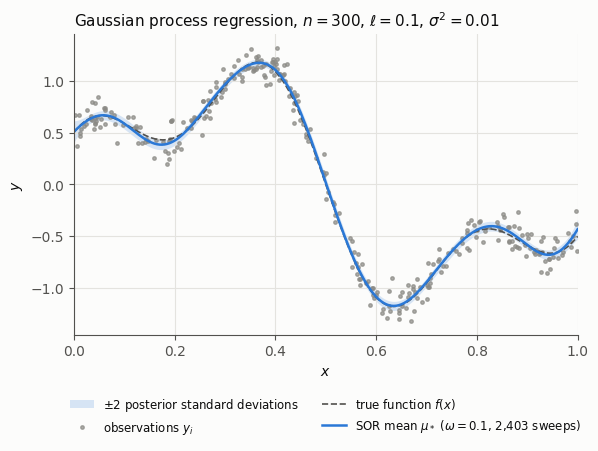

In [13]:
main_study = STUDY[0.1, 0.01]
_, alpha_sor = sor_until(MAIN.A, MAIN.y, main_study["w_best"], ERROR_MAIN, TARGET, MAX_SWEEPS)
mu_sor = MAIN.K_star @ alpha_sor

fig, ax = plt.subplots(figsize=(6.5, 3.9))
ax.fill_between(MAIN.x_star, mu_main - 2 * POSTERIOR_SD, mu_main + 2 * POSTERIOR_SD, color=BLUE, alpha=0.18,
                linewidth=0, label=r"$\pm 2$ posterior standard deviations")
ax.plot(MAIN.x, MAIN.y, "o", markersize=2.5, color=REFERENCE, alpha=0.7, label="observations $y_i$")
ax.plot(MAIN.x_star, true_function(MAIN.x_star), color=INK_2, linestyle="--", linewidth=1.2,
        label="true function $f(x)$")
ax.plot(MAIN.x_star, mu_sor, color=BLUE,
        label=rf"SOR mean $\mu_*$ ($\omega = {main_study['w_best']}$, {main_study['best']:,} sweeps)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False, fontsize=8.5)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_xlim(0, 1)
ax.set_title(r"Gaussian process regression, $n = 300$, $\ell = 0.1$, $\sigma^2 = 0.01$", loc="left")

fig.savefig("figures/fig6_gpr_fit.pdf")
plt.show()

### Figure 7: The effect of $\omega$ on GPR systems

Three length scales, all with $\sigma^2 = 0.01$ and $n = 300$. Top: measured sweeps until the predictive mean
is within 0.1% (runs that hit the 20,000-sweep limit are not plotted). Bottom: the sweeps per decimal digit
of $\boldsymbol\alpha$ predicted by $\rho(T_\omega)$, $1/(-\log_{10}\rho)$. Hollow markers are Gauss-Seidel,
filled markers are the best $\omega$. The vertical axes are logarithmic. Computing the spectral radii takes
about ten seconds.

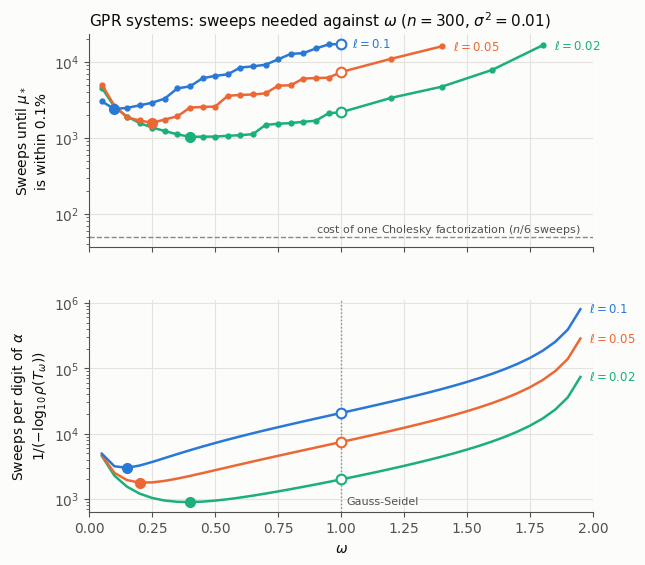

In [14]:
CURVES = [(0.02, AQUA), (0.05, ORANGE), (0.1, BLUE)]
RHO_CURVES = {ell: np.array([spectral_radius(sor_matrix(STUDY[ell, 0.01]["problem"].A, w)) for w in GPR_OMEGAS])
              for ell, _ in CURVES}

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.5, 6.2), sharex=True, gridspec_kw={"hspace": 0.25})
for ell, color in CURVES:
    s = STUDY[ell, 0.01]
    top.plot(SWEEP_OMEGAS, s["sweeps"], color=color, marker="o", markersize=3.5)
    top.plot(1.0, s["gs"], "o", markersize=7, color=SURFACE, markeredgecolor=color, markeredgewidth=1.5, zorder=3)
    top.plot(s["w_best"], s["best"], "o", markersize=7, color=color, zorder=3)
    last = np.flatnonzero(np.isfinite(s["sweeps"]))[-1]
    top.annotate(rf"$\ell = {ell}$", (SWEEP_OMEGAS[last], s["sweeps"][last]), xytext=(8, 0),
                 textcoords="offset points", va="center", fontsize=8.5, color=color)

    per_digit = sweeps_per_digit(RHO_CURVES[ell])
    j = np.argmin(RHO_CURVES[ell])
    bottom.plot(GPR_OMEGAS, per_digit, color=color)
    bottom.plot(1.0, per_digit[GPR_OMEGAS == 1.0][0], "o", markersize=7, color=SURFACE, markeredgecolor=color,
                markeredgewidth=1.5, zorder=3)
    bottom.plot(GPR_OMEGAS[j], per_digit[j], "o", markersize=7, color=color, zorder=3)
    bottom.annotate(rf"$\ell = {ell}$", (GPR_OMEGAS[-1], per_digit[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=color, annotation_clip=False)

top.axhline(300 / 6, color=REFERENCE, linestyle="--", linewidth=1)
top.text(1.95, 300 / 6 * 1.15, "cost of one Cholesky factorization ($n/6$ sweeps)", ha="right",
         fontsize=8, color=INK_2)
top.set_yscale("log")
top.set_ylabel("Sweeps until $\\mu_*$\nis within 0.1%")
top.set_title(r"GPR systems: sweeps needed against $\omega$ ($n = 300$, $\sigma^2 = 0.01$)", loc="left")
bottom.set_yscale("log")
bottom.set_ylabel("Sweeps per digit of $\\alpha$\n$1/(-\\log_{10}\\rho(T_\\omega))$")
bottom.set_xlabel(r"$\omega$")
bottom.set_xlim(0, 2)
bottom.axvline(1, color=REFERENCE, linestyle=":", linewidth=1)
bottom.text(1.02, bottom.get_ylim()[0] * 1.3, "Gauss-Seidel", fontsize=8, color=INK_2)

fig.savefig("figures/fig7_gpr_omega.pdf")
plt.show()

### Figure 8: Work needed as the number of observations grows

$\ell = 0.05$, $\sigma^2 = 0.01$. Both axes are logarithmic. The dashed line is the break-even count $n/6$:
a method above it costs more than solving the system directly by Cholesky factorization.

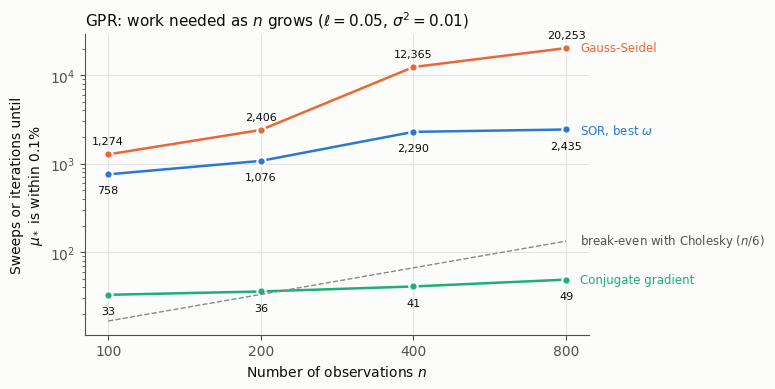

In [15]:
ns = np.array([row["n"] for row in GPR_SCALING])
fig, ax = plt.subplots(figsize=(6.5, 3.9))
series = [("gs", ORANGE, "Gauss-Seidel"), ("sor", BLUE, r"SOR, best $\omega$"), ("cg", AQUA, "Conjugate gradient")]
for key, color, label in series:
    counts = np.array([row[key] or np.nan for row in GPR_SCALING], dtype=float)
    ax.plot(ns, counts, color=color, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    for n_, k in zip(ns, counts):
        if np.isfinite(k):
            ax.annotate(f"{k:,.0f}", (n_, k), xytext=(0, 7 if key == "gs" else -14), textcoords="offset points",
                        ha="center", fontsize=8)
    ax.annotate(label, (ns[-1], counts[-1]), xytext=(10, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=color, annotation_clip=False)

ax.plot(ns, ns / 6, color=REFERENCE, linestyle="--", linewidth=1)
ax.annotate("break-even with Cholesky ($n/6$)", (ns[-1], ns[-1] / 6), xytext=(10, 0), textcoords="offset points",
            va="center", fontsize=8.5, color=INK_2, annotation_clip=False)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(ns)
ax.set_xticklabels([str(n_) for n_ in ns])
ax.set_xlabel("Number of observations $n$")
ax.set_ylabel("Sweeps or iterations until\n$\\mu_*$ is within 0.1%")
ax.set_title(r"GPR: work needed as $n$ grows ($\ell = 0.05$, $\sigma^2 = 0.01$)", loc="left")

fig.savefig("figures/fig8_gpr_scaling.pdf")
plt.show()

## References

1. R. L. Burden, J. D. Faires and A. M. Burden, *Numerical Analysis*, 10th ed., Cengage Learning, 2016.
   Section 6.6 (Cholesky factorization), Section 7.3 (Jacobi and Gauss-Seidel, Theorem 7.21), Section 7.4
   (relaxation techniques, Algorithm 7.3, Theorems 7.24 to 7.26) and Section 7.6 (the conjugate gradient
   method, Algorithm 7.5).
2. C. E. Rasmussen and C. K. I. Williams, *Gaussian Processes for Machine Learning*, MIT Press, 2006,
   Chapter 2. https://gaussianprocess.org/gpml/chapters/
3. A. G. Wilson and H. Nickisch, Kernel interpolation for scalable structured Gaussian processes (KISS-GP),
   *Proceedings of the 32nd International Conference on Machine Learning*, PMLR 37, 2015.
   https://proceedings.mlr.press/v37/wilson15.pdf